In [2]:
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv('placement.csv')

In [4]:
df.sample(5)

,Unnamed: 0,cgpa,iq,placement
39,39,4.6,146.0,0
11,11,6.9,138.0,1
90,90,7.3,86.0,1
94,94,4.7,52.0,0
66,66,6.9,96.0,1


In [5]:
df.drop(columns=['Unnamed: 0'],inplace=True)

In [6]:
df

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0
...,...,...,...
95,4.3,200.0,0
96,4.4,42.0,0
97,6.7,182.0,1
98,6.3,103.0,1


In [7]:
len(df)

100

In [8]:
df.describe()

,cgpa,iq,placement
count,100.000000,100.000000,100.000000
mean,5.991000,123.580000,0.500000
std,1.143634,39.944198,0.502519
min,3.300000,37.000000,0.000000
25%,5.075000,101.500000,0.000000
50%,6.000000,127.500000,0.500000
75%,6.900000,149.000000,1.000000
max,8.500000,233.000000,1.000000


In [9]:
x = df.drop(columns=['placement'])

In [10]:
y = df['placement']

In [ ]:
from sklearn.linear_model import LogisticRegression

In [12]:
from sklearn.metrics import r2_score

In [13]:
model = LogisticRegression()


In [14]:
model.fit(x,y)



LogisticRegression()

In [15]:
y_pred = model.predict(x)

In [52]:
y

0     1
1     0
2     0
3     1
4     0
     ..
95    0
96    0
97    1
98    1
99    1
Name: placement, Length: 100, dtype: int64

In [51]:
y_pred

array([1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1,
       1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0,
       0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1], dtype=int64)

In [16]:
score = r2_score(y,y_pred)

In [17]:
score


0.72

In [18]:
x_new = np.array([[6.8,123]])

In [19]:
y_pred_new = model.predict(x_new)

d:\Anaconda\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [20]:
y_pred_new

array([1], dtype=int64)

In [56]:
x_new_2 = np.array([[6.9,166]])

In [57]:
y_pred_new_2 = model.predict(x_new_2)

d:\Anaconda\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [58]:
y_pred_new_2

array([1], dtype=int64)

# Lets Do It With Split

In [24]:
from sklearn.model_selection import train_test_split

In [25]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [26]:
model_2 = LogisticRegression()

In [27]:
model_2.fit(x_train,y_train)

LogisticRegression()

In [28]:
y_pred_model_2 = model_2.predict(x_test)

In [29]:
score_model_2 = r2_score(y_test,y_pred_model_2)

In [30]:
score_model_2

0.4

# Lets Standardize

In [31]:
from sklearn.preprocessing import StandardScaler

In [32]:
scaler = StandardScaler()
model_3 = LogisticRegression()

In [33]:
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [34]:
x_train.shape


(80, 2)

In [35]:
x_train_scaled.shape

(80, 2)

In [36]:
x_test.shape

(20, 2)

In [37]:

x_test_scaled.shape

(20, 2)

In [38]:
model_3.fit(x_train_scaled,y_train)

LogisticRegression()

In [39]:
y_pred_model_3 = model_3.predict(x_test_scaled)

In [40]:
score_3 = r2_score(y_pred_model_3,y_test)

In [50]:
score_3

0.3939393939393939

d:\Anaconda\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


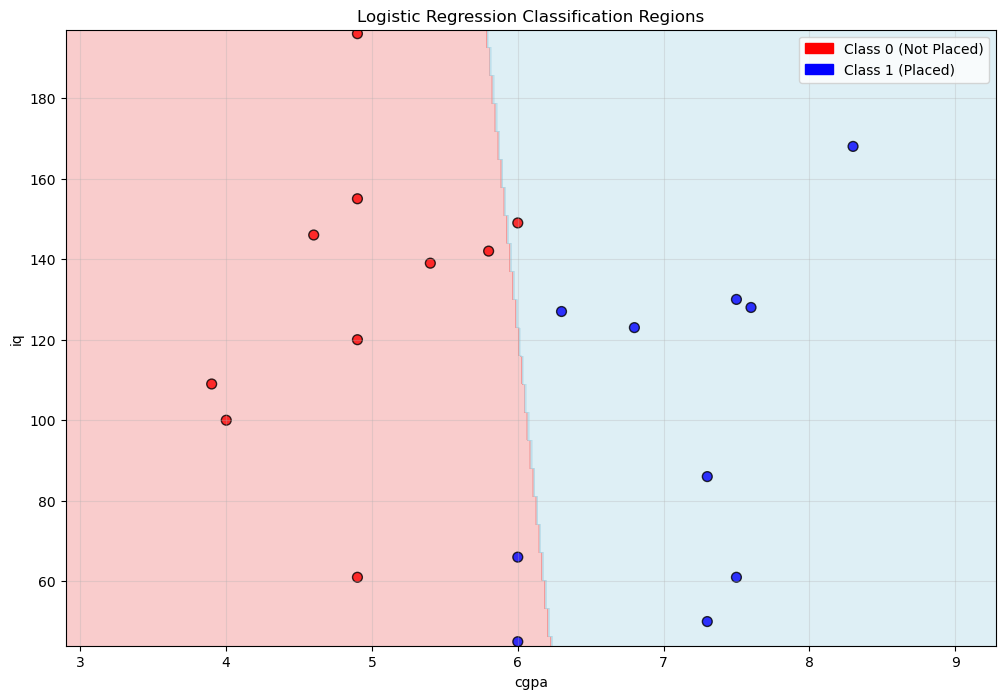

In [47]:
# Classification Regions Plot for Logistic Regression
from matplotlib.colors import ListedColormap
import matplotlib.patches as mpatches

# Create a mesh grid for classification regions
def plot_decision_regions(X, y, classifier, resolution=0.02):
    """
    Plot decision regions for 2D classification
    """
    # Get feature names
    feature_names = X.columns.tolist()
    
    # Create a mesh grid
    x_min, x_max = X.iloc[:, 0].min() - 1, X.iloc[:, 0].max() + 1
    y_min, y_max = X.iloc[:, 1].min() - 1, X.iloc[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, resolution),
                         np.arange(y_min, y_max, resolution))
    
    # Make predictions on the mesh grid
    mesh_points = np.c_[xx.ravel(), yy.ravel()]
    Z = classifier.predict(mesh_points)
    Z = Z.reshape(xx.shape)
    
    # Plot the decision regions
    plt.figure(figsize=(12, 8))
    plt.contourf(xx, yy, Z, alpha=0.4, cmap=ListedColormap(['lightcoral', 'lightblue']))
    
    # Plot the actual data points
    scatter = plt.scatter(X.iloc[:, 0], X.iloc[:, 1], c=y, cmap=ListedColormap(['red', 'blue']), 
                         edgecolors='black', s=50, alpha=0.8)
    
    plt.xlabel(feature_names[0])
    plt.ylabel(feature_names[1])
    plt.title('Logistic Regression Classification Regions')
    
    # Create legend
    red_patch = mpatches.Patch(color='red', label='Class 0 (Not Placed)')
    blue_patch = mpatches.Patch(color='blue', label='Class 1 (Placed)')
    plt.legend(handles=[red_patch, blue_patch])
    
    plt.grid(True, alpha=0.3)
    plt.show()

# Plot decision regions for the logistic regression model
plot_decision_regions(x_test, y_test, model_2)


d:\Anaconda\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


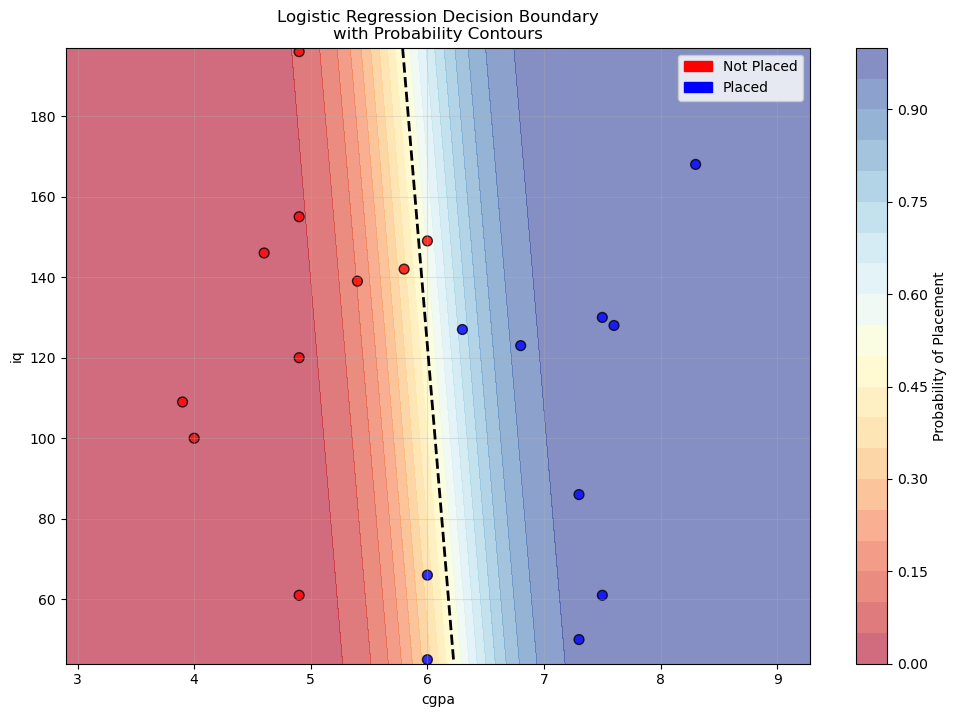

In [48]:
# Alternative: Decision Boundary with Probability Contours
def plot_decision_boundary_with_probability(X, y, classifier, resolution=0.02):
    """
    Plot decision boundary with probability contours
    """
    feature_names = X.columns.tolist()
    
    # Create mesh grid
    x_min, x_max = X.iloc[:, 0].min() - 1, X.iloc[:, 0].max() + 1
    y_min, y_max = X.iloc[:, 1].min() - 1, X.iloc[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, resolution),
                         np.arange(y_min, y_max, resolution))
    
    # Get probability predictions
    mesh_points = np.c_[xx.ravel(), yy.ravel()]
    Z_proba = classifier.predict_proba(mesh_points)[:, 1]  # Probability of class 1
    Z_proba = Z_proba.reshape(xx.shape)
    
    # Plot probability contours
    plt.figure(figsize=(12, 8))
    contour = plt.contourf(xx, yy, Z_proba, levels=20, cmap='RdYlBu', alpha=0.6)
    plt.colorbar(contour, label='Probability of Placement')
    
    # Plot decision boundary (where probability = 0.5)
    plt.contour(xx, yy, Z_proba, levels=[0.5], colors='black', linestyles='--', linewidths=2)
    
    # Plot actual data points
    scatter = plt.scatter(X.iloc[:, 0], X.iloc[:, 1], c=y, cmap=ListedColormap(['red', 'blue']), 
                         edgecolors='black', s=50, alpha=0.8)
    
    plt.xlabel(feature_names[0])
    plt.ylabel(feature_names[1])
    plt.title('Logistic Regression Decision Boundary\nwith Probability Contours')
    
    # Create legend
    red_patch = mpatches.Patch(color='red', label='Not Placed')
    blue_patch = mpatches.Patch(color='blue', label='Placed')
    plt.legend(handles=[red_patch, blue_patch])
    
    plt.grid(True, alpha=0.3)
    plt.show()

# Plot decision boundary with probability contours
plot_decision_boundary_with_probability(x_test, y_test, model_2)
